In [1]:
## CLUSTERING
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [3]:
from sklearn.datasets import load_wine
## Import the Wine dataset from SciKit-Learn
wine_bunch = load_wine()
# Allocating this data to a Data Frame
wine = pd.DataFrame(wine_bunch.data)
# Use the feature_names attribute to give sensible column headings
# Assigning wine.columns to col names for use later
col_names = list(wine_bunch.feature_names)
# Once colum has a lenghty name, we rename this for ease of display
# od280/od315_of_diluted_wines -> od280_od315
col_names[11] = 'od280_od315'
wine.columns = col_names
# I am adding a 1 to the 'real classes' columns to avoid having to talk about 'cluster 0'
# We will start the count from 1
wine['real_classes'] = wine_bunch.target + 1
wine.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280_od315,proline,real_classes
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,1
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,1
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,1
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,1
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,1


In [5]:
wine.describe()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280_od315,proline,real_classes
count,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000
mean,13.000618,2.336348,2.366517,19.494944,99.741573,2.295112,2.029270,0.361854,1.590899,5.058090,0.957449,2.611685,746.893258,1.938202
std,0.811827,1.117146,0.274344,3.339564,14.282484,0.625851,0.998859,0.124453,0.572359,2.318286,0.228572,0.709990,314.907474,0.775035
min,11.030000,0.740000,1.360000,10.600000,70.000000,0.980000,0.340000,0.130000,0.410000,1.280000,0.480000,1.270000,278.000000,1.000000
25%,12.362500,1.602500,2.210000,17.200000,88.000000,1.742500,1.205000,0.270000,1.250000,3.220000,0.782500,1.937500,500.500000,1.000000
50%,13.050000,1.865000,2.360000,19.500000,98.000000,2.355000,2.135000,0.340000,1.555000,4.690000,0.965000,2.780000,673.500000,2.000000
75%,13.677500,3.082500,2.557500,21.500000,107.000000,2.800000,2.875000,0.437500,1.950000,6.200000,1.120000,3.170000,985.000000,3.000000
max,14.830000,5.800000,3.230000,30.000000,162.000000,3.880000,5.080000,0.660000,3.580000,13.000000,1.710000,4.000000,1680.000000,3.000000


In [6]:
wine.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   alcohol               178 non-null    float64
 1   malic_acid            178 non-null    float64
 2   ash                   178 non-null    float64
 3   alcalinity_of_ash     178 non-null    float64
 4   magnesium             178 non-null    float64
 5   total_phenols         178 non-null    float64
 6   flavanoids            178 non-null    float64
 7   nonflavanoid_phenols  178 non-null    float64
 8   proanthocyanins       178 non-null    float64
 9   color_intensity       178 non-null    float64
 10  hue                   178 non-null    float64
 11  od280_od315           178 non-null    float64
 12  proline               178 non-null    float64
 13  real_classes          178 non-null    int64  
dtypes: float64(13), int64(1)
memory usage: 19.6 KB


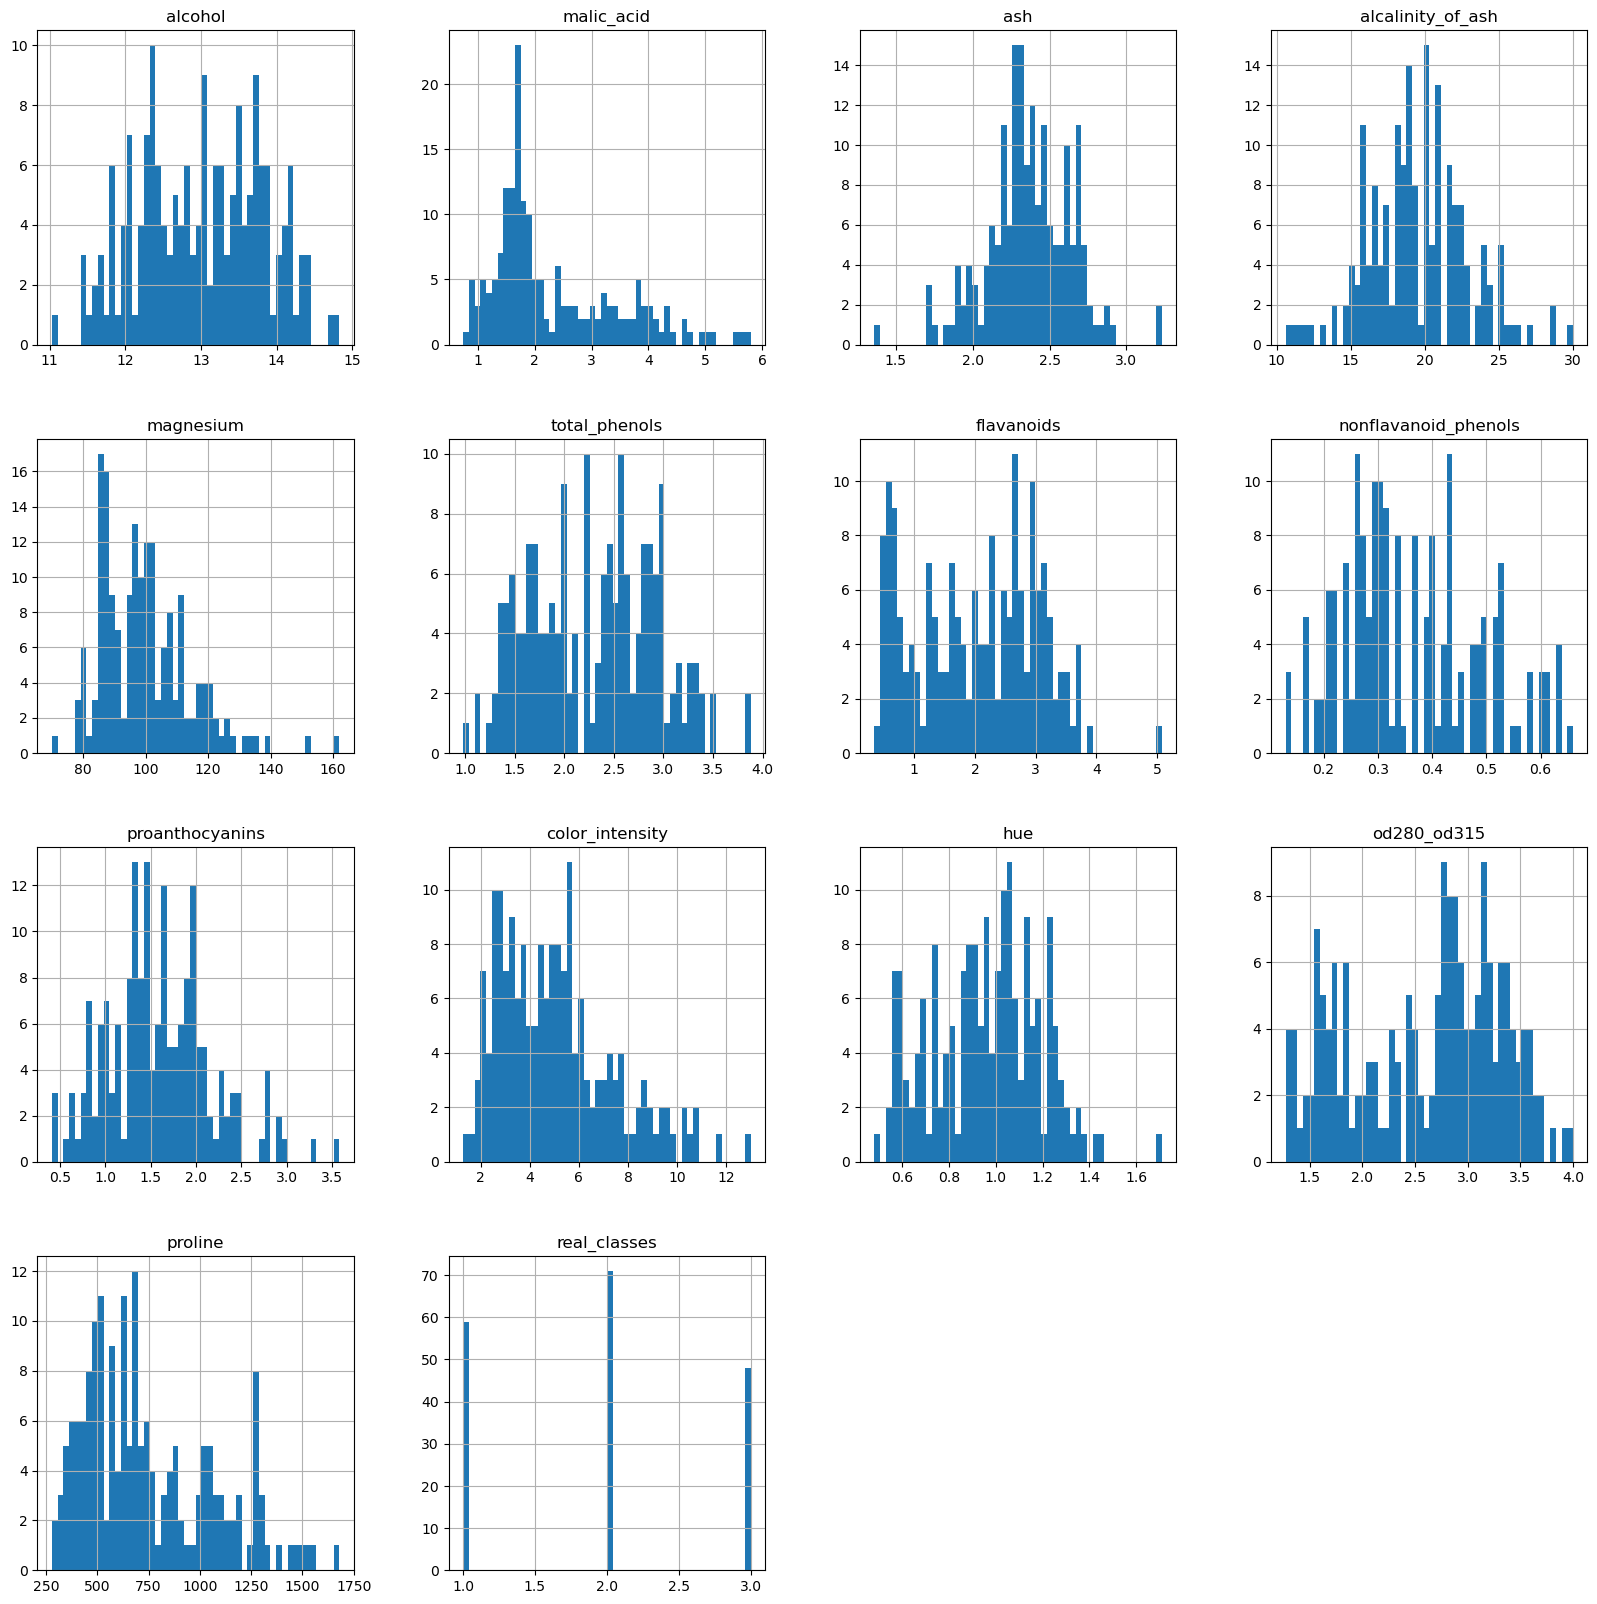

In [8]:
## visualising the distribution
wine.hist(bins = 50, figsize=(20,20));

In [9]:
## checking if there is any null
wine.isna().sum()

alcohol                 0
malic_acid              0
ash                     0
alcalinity_of_ash       0
magnesium               0
total_phenols           0
flavanoids              0
nonflavanoid_phenols    0
proanthocyanins         0
color_intensity         0
hue                     0
od280_od315             0
proline                 0
real_classes            0
dtype: int64

array([[<Axes: xlabel='alcohol', ylabel='alcohol'>,
        <Axes: xlabel='malic_acid', ylabel='alcohol'>,
        <Axes: xlabel='ash', ylabel='alcohol'>,
        <Axes: xlabel='alcalinity_of_ash', ylabel='alcohol'>,
        <Axes: xlabel='magnesium', ylabel='alcohol'>,
        <Axes: xlabel='total_phenols', ylabel='alcohol'>,
        <Axes: xlabel='flavanoids', ylabel='alcohol'>,
        <Axes: xlabel='nonflavanoid_phenols', ylabel='alcohol'>,
        <Axes: xlabel='proanthocyanins', ylabel='alcohol'>,
        <Axes: xlabel='color_intensity', ylabel='alcohol'>,
        <Axes: xlabel='hue', ylabel='alcohol'>,
        <Axes: xlabel='od280_od315', ylabel='alcohol'>,
        <Axes: xlabel='proline', ylabel='alcohol'>,
        <Axes: xlabel='real_classes', ylabel='alcohol'>],
       [<Axes: xlabel='alcohol', ylabel='malic_acid'>,
        <Axes: xlabel='malic_acid', ylabel='malic_acid'>,
        <Axes: xlabel='ash', ylabel='malic_acid'>,
        <Axes: xlabel='alcalinity_of_ash', ylabel='ma

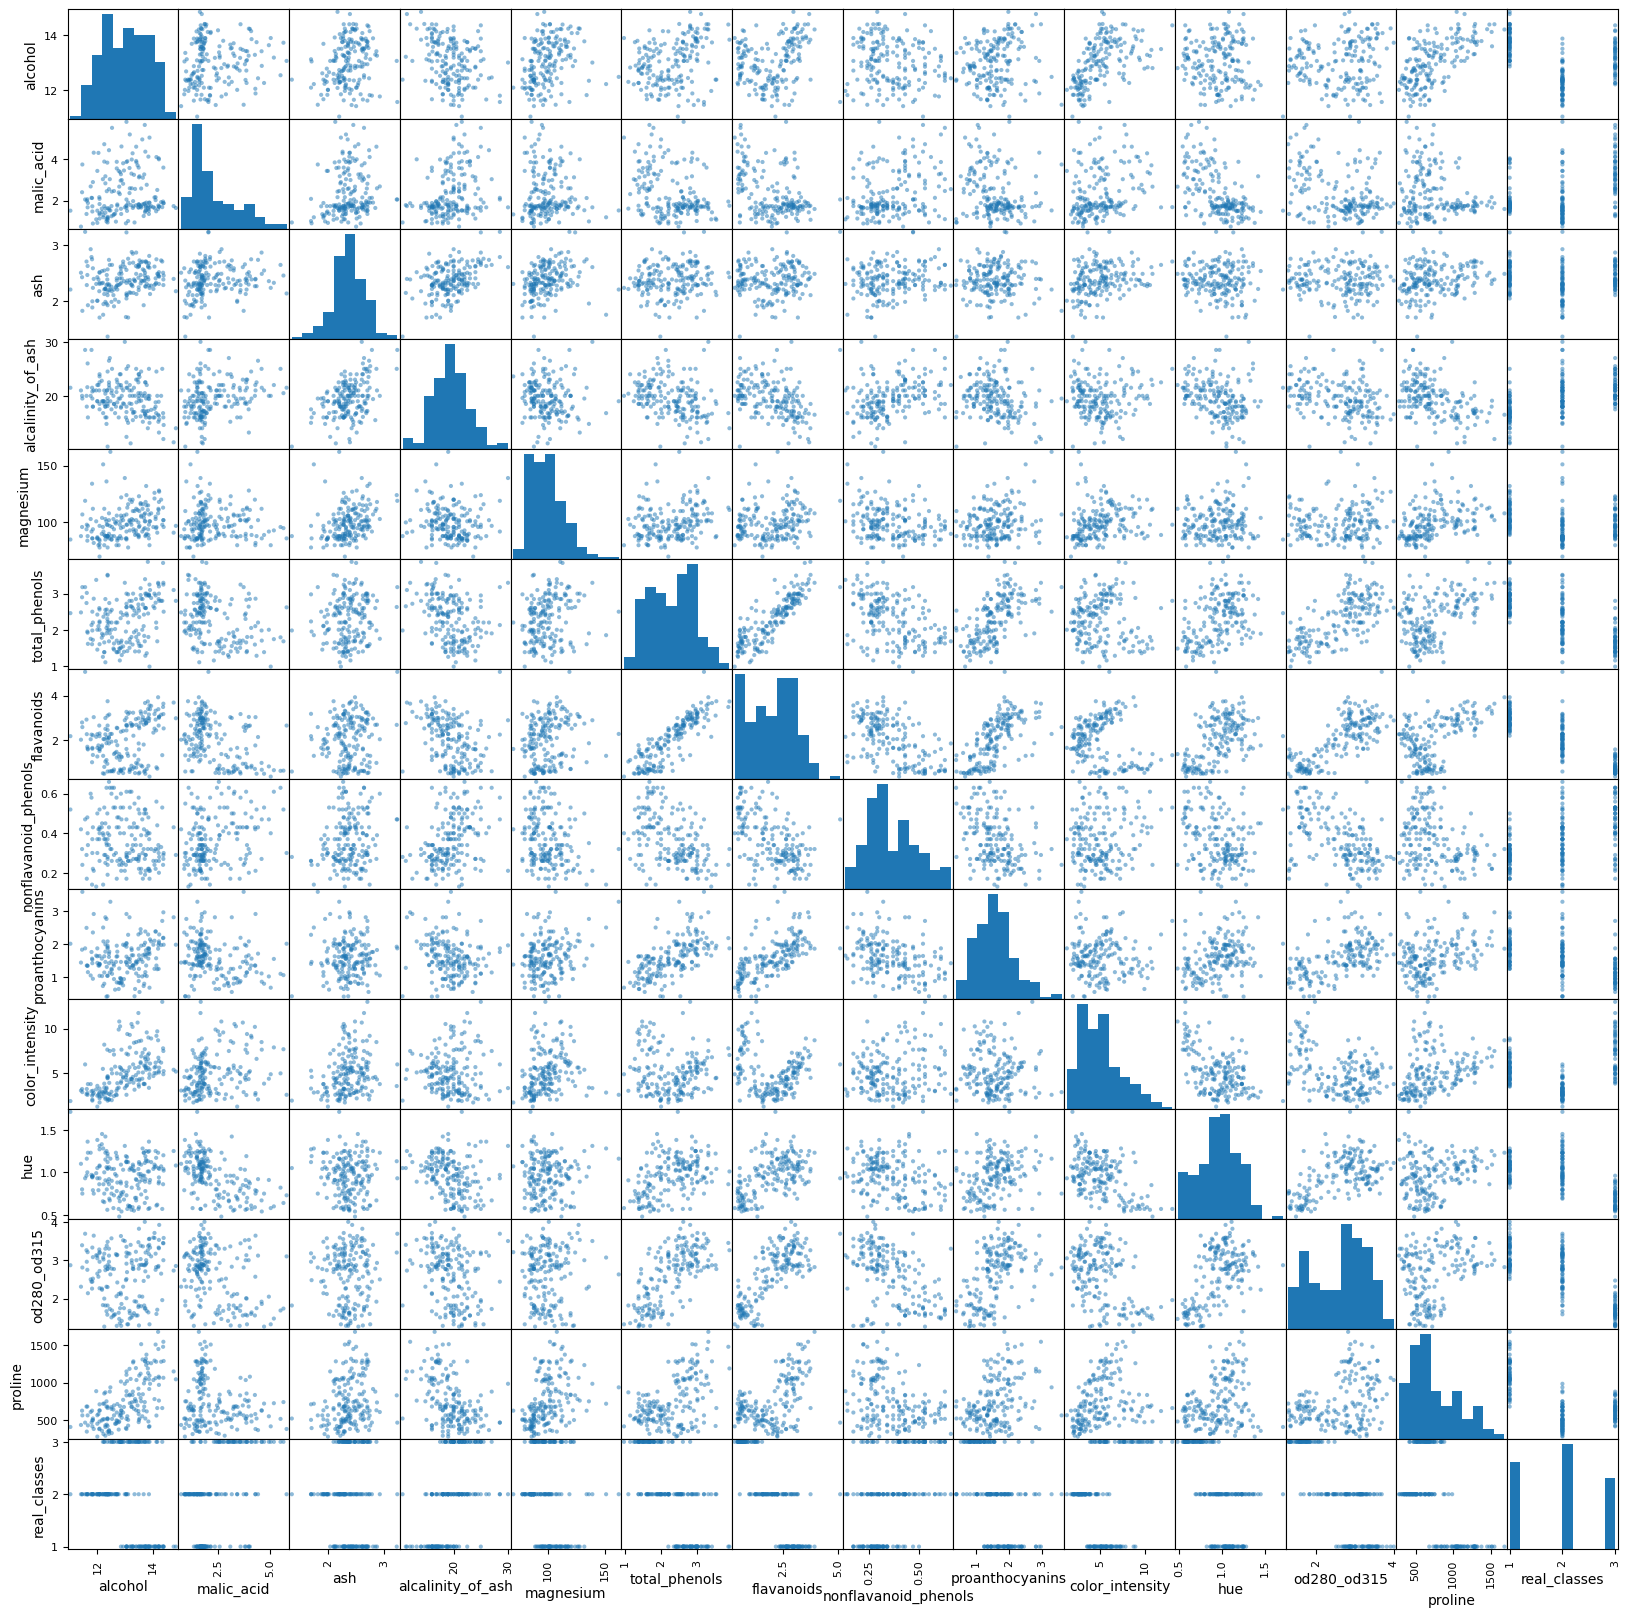

In [10]:
## scatter plot to see obvious patterns
pd.plotting.scatter_matrix(wine, figsize=(20,20))

In [11]:
## Building the clustering model
from sklearn.cluster import KMeans


In [15]:
# creating a kmeans model called kmeans1
kmeans1 = KMeans(n_clusters=2).fit(wine[col_names])

In [16]:
# Storing the centroids
## The centroids can be extracted
centroids1 = kmeans1.cluster_centers_
## This is the list of allocated classes
labels1 = kmeans1.labels_
## Appending these labels to our original dataframe
# I added 1 again to avoid talking about class 0
wine['kmeans1'] = labels1 + 1

In [17]:
## mean value of each feature per group label
wine.groupby('kmeans1').mean()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280_od315,proline,real_classes
kmeans1,,,,,,,,,,,,,,
1,12.702846,2.544553,2.339106,20.408130,96.813008,2.062114,1.641463,0.392683,1.454065,4.851382,0.908618,2.408211,565.869919,2.308943
2,13.666545,1.870727,2.427818,17.452727,106.290909,2.816182,2.896545,0.292909,1.896909,5.520364,1.066655,3.066727,1151.727273,1.109091


In [ ]:
## TODO: Understand the key differences above

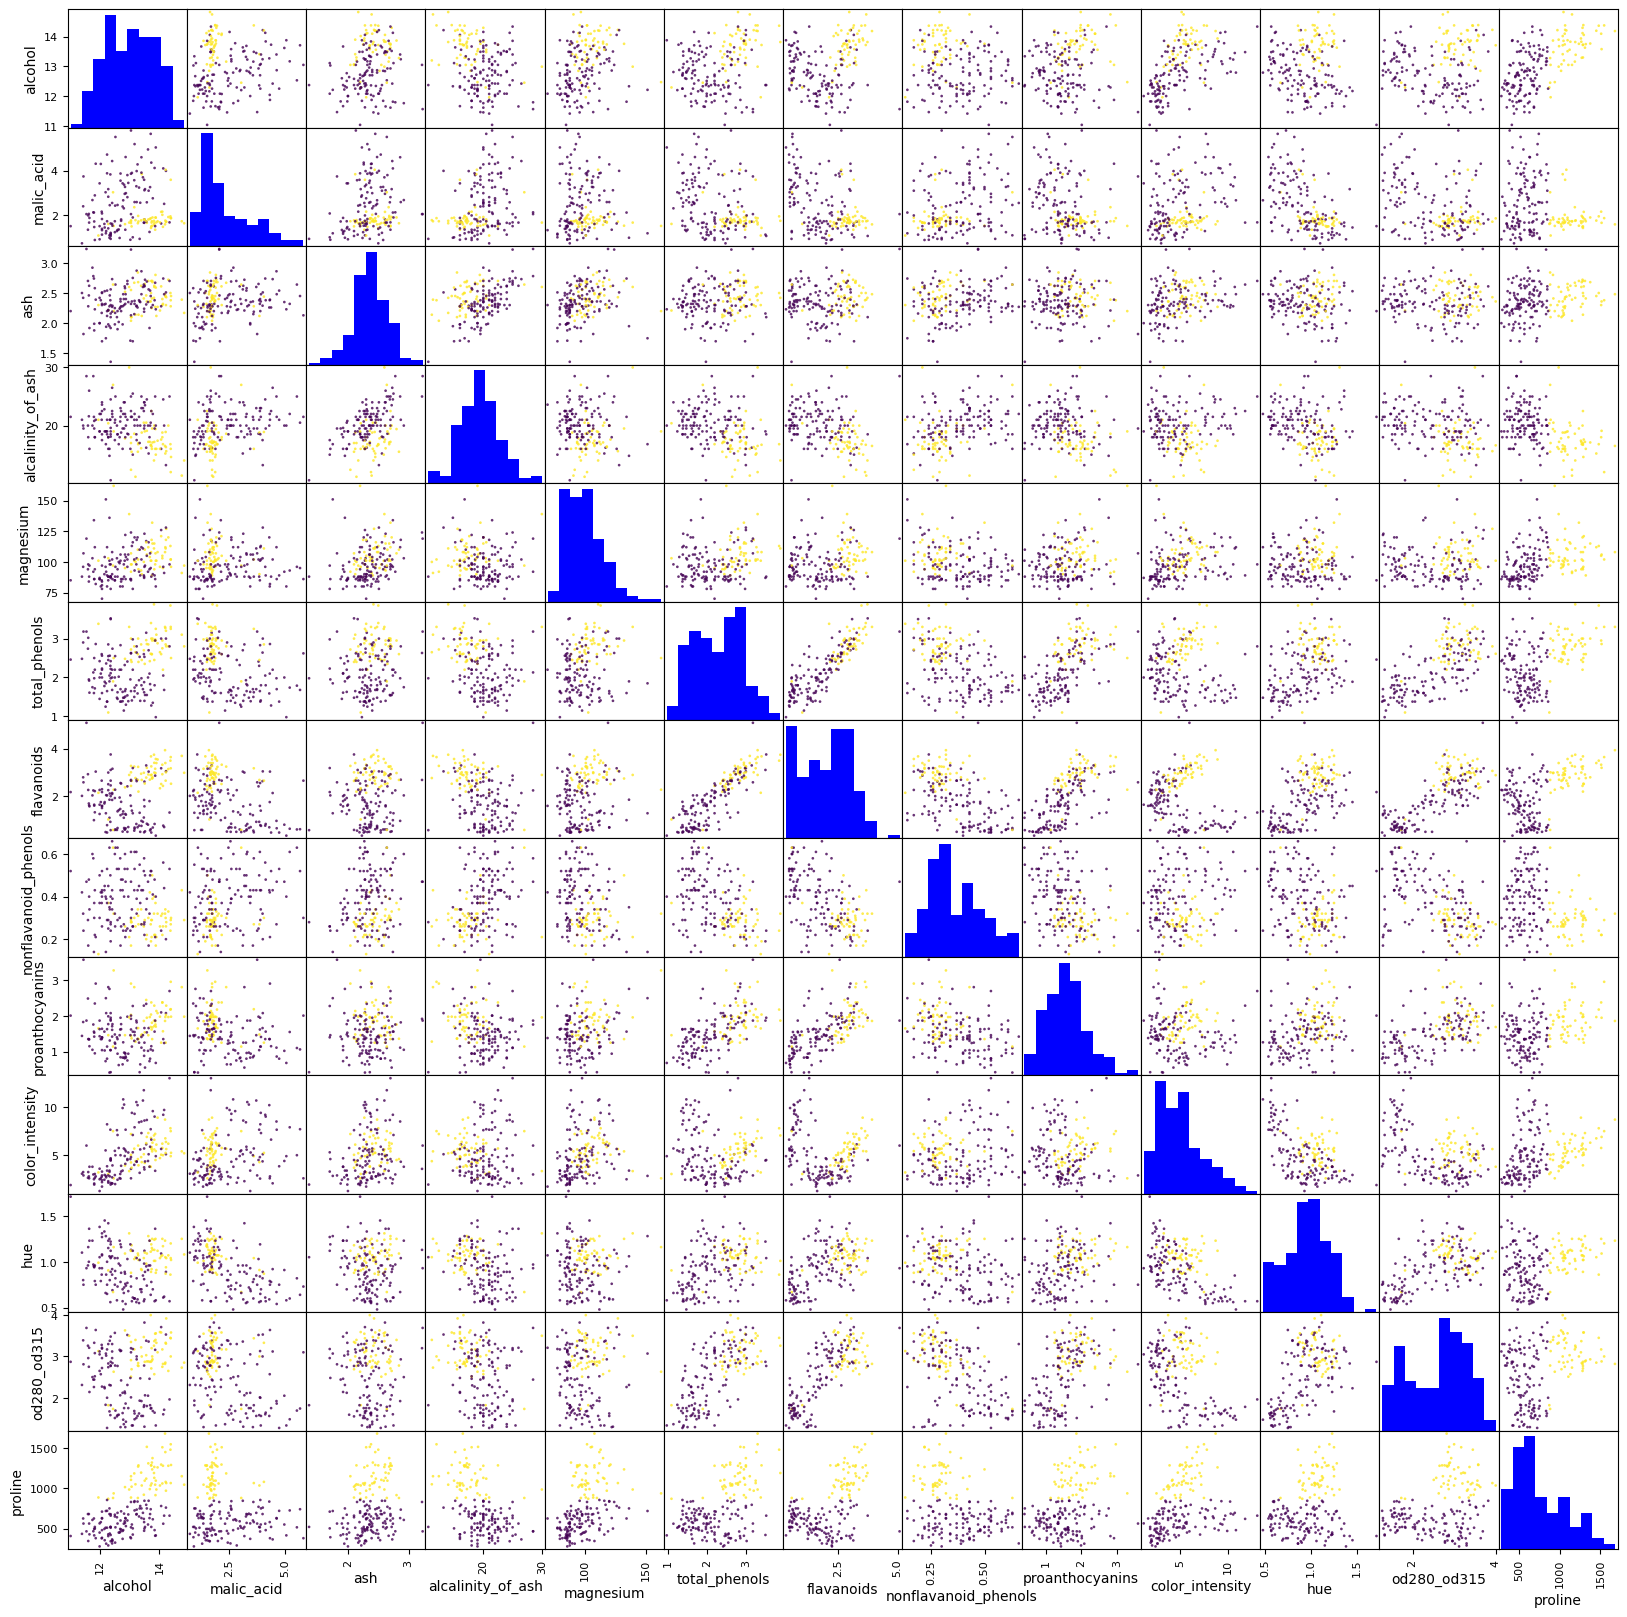

In [ ]:
## Plotting clustered data
## TODO: Understand the code below
import matplotlib as mpl
mpl.rcParams['axes.prop_cycle'] = mpl.cycler(color=["b", "r", "g"])
plot = pd.plotting.scatter_matrix(wine[col_names],
figsize=(20,20),
marker = '.',
s = 15,
alpha = 0.8,
c = wine['kmeans1'])

In [ ]:
## actual label vs predicted label for each group
##Q : What does unstack() do
wine.groupby(['kmeans1', 'real_classes'])['real_classes'].count().unstack()

real_classes,1,2,3
kmeans1,,,
1,9,67,47
2,50,4,1


In [43]:
## Using 3 columns instead of 2
kmeans2 = KMeans(n_clusters=3).fit(wine[col_names])

# Storing the centroids
## The centroids can be extracted
centroids2 = kmeans2.cluster_centers_
## This is the list of allocated classes
labels2 = kmeans2.labels_
## Appending these labels to our original dataframe
# I added 1 again to avoid talking about class 0
wine['kmeans2'] = labels2 + 1



In [27]:
## mean value of each feature per group label
wine.groupby('kmeans2').mean()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280_od315,proline,real_classes,kmeans1
kmeans2,,,,,,,,,,,,,,,
1,12.516667,2.494203,2.288551,20.823188,92.347826,2.070725,1.758406,0.390145,1.451884,4.086957,0.941159,2.490725,458.231884,2.275362,2.000000
2,13.804468,1.883404,2.426170,17.023404,105.510638,2.867234,3.014255,0.285319,1.910426,5.702553,1.078298,3.114043,1195.148936,1.021277,1.851064
3,12.929839,2.504032,2.408065,19.890323,103.596774,2.111129,1.584032,0.388387,1.503387,5.650323,0.883968,2.365484,728.338710,2.258065,2.467742


In [44]:
## actual label vs predicted label for each group
##Q : What does unstack() do
wine.groupby(['kmeans2', 'real_classes'])['real_classes'].count().unstack()

real_classes,1,2,3
kmeans2,,,
1,13.0,20.0,29.0
2,46.0,1.0,NaN
3,NaN,50.0,19.0


In [30]:
## specific columns
new_cols = ['alcohol', 'alcalinity_of_ash','magnesium','color_intensity','proline']

In [31]:
kmeans3 = KMeans(n_clusters=3).fit(wine[new_cols])

In [45]:


# Storing the centroids
## The centroids can be extracted
centroids3 = kmeans3.cluster_centers_
## This is the list of allocated classes
labels3 = kmeans3.labels_
## Appending these labels to our original dataframe
# I added 1 again to avoid talking about class 0
wine['kmeans3'] = labels3 + 1

In [33]:
## mean value of each feature per group label
wine.groupby('kmeans3').mean()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280_od315,proline,real_classes,kmeans1,kmeans2
kmeans3,,,,,,,,,,,,,,,,
1,12.929839,2.504032,2.408065,19.890323,103.596774,2.111129,1.584032,0.388387,1.503387,5.650323,0.883968,2.365484,728.338710,2.258065,2.467742,3.0
2,13.804468,1.883404,2.426170,17.023404,105.510638,2.867234,3.014255,0.285319,1.910426,5.702553,1.078298,3.114043,1195.148936,1.021277,1.851064,2.0
3,12.516667,2.494203,2.288551,20.823188,92.347826,2.070725,1.758406,0.390145,1.451884,4.086957,0.941159,2.490725,458.231884,2.275362,2.000000,1.0


In [34]:
wine.groupby(['kmeans3', 'real_classes'])['real_classes'].count().unstack()

real_classes,1,2,3
kmeans3,,,
1,13.0,20.0,29.0
2,46.0,1.0,NaN
3,NaN,50.0,19.0


In [ ]:
## Answer this question
## How does this model with five features compare to the model with all?
## Why do you think this is the case? What would you do to resolve the issue?

In [36]:
## scaling
from sklearn import preprocessing


In [38]:
## define columns to scale
cols_to_scale = col_names

## min max scaler
min_max_scaler = preprocessing.MinMaxScaler()

In [39]:
## Fitting the scalar to the two named columns and creating a new DataFrame
wine_std = pd.DataFrame(min_max_scaler.fit_transform(wine[cols_to_scale]), columns = min_max_scaler.get_feature_names_out())

In [40]:
wine_std

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280_od315,proline
0,0.842105,0.191700,0.572193,0.257732,0.619565,0.627586,0.573840,0.283019,0.593060,0.372014,0.455285,0.970696,0.561341
1,0.571053,0.205534,0.417112,0.030928,0.326087,0.575862,0.510549,0.245283,0.274448,0.264505,0.463415,0.780220,0.550642
2,0.560526,0.320158,0.700535,0.412371,0.336957,0.627586,0.611814,0.320755,0.757098,0.375427,0.447154,0.695971,0.646933
3,0.878947,0.239130,0.609626,0.319588,0.467391,0.989655,0.664557,0.207547,0.558360,0.556314,0.308943,0.798535,0.857347
4,0.581579,0.365613,0.807487,0.536082,0.521739,0.627586,0.495781,0.490566,0.444795,0.259386,0.455285,0.608059,0.325963
...,...,...,...,...,...,...,...,...,...,...,...,...,...
173,0.705263,0.970356,0.582888,0.510309,0.271739,0.241379,0.056962,0.735849,0.205047,0.547782,0.130081,0.172161,0.329529
174,0.623684,0.626482,0.598930,0.639175,0.347826,0.282759,0.086498,0.566038,0.315457,0.513652,0.178862,0.106227,0.336662
175,0.589474,0.699605,0.481283,0.484536,0.543478,0.210345,0.073840,0.566038,0.296530,0.761092,0.089431,0.106227,0.397290
176,0.563158,0.365613,0.540107,0.484536,0.543478,0.231034,0.071730,0.754717,0.331230,0.684300,0.097561,0.128205,0.400856


In [41]:
## fitting the model
kmeans4 = KMeans(n_clusters=3).fit(wine_std)

In [46]:
# Storing the centroids
## The centroids can be extracted
centroids4 = kmeans4.cluster_centers_
## This is the list of allocated classes
labels4 = kmeans4.labels_
## Appending these labels to our original dataframe
# I added 1 again to avoid talking about class 0
wine['kmeans4'] = labels4 + 1

In [47]:
wine.groupby('kmeans4').mean()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280_od315,proline,real_classes,kmeans1,kmeans2,kmeans3
kmeans4,,,,,,,,,,,,,,,,,
1,12.202742,1.946774,2.249839,20.211290,93.451613,2.200806,2.038710,0.369032,1.607903,2.949355,1.056387,2.801129,502.709677,2.000000,2.064516,2.451613,2.451613
2,13.656923,1.946154,2.437692,17.441538,106.584615,2.864615,2.970000,0.284308,1.923846,5.361692,1.071385,3.148923,1080.107692,1.092308,2.107692,1.784615,1.784615
3,13.134118,3.307255,2.417647,21.241176,98.666667,1.683922,0.818824,0.451961,1.145882,7.234706,0.691961,1.696667,619.058824,2.941176,2.215686,1.862745,1.862745


In [48]:
wine.groupby(['kmeans4', 'real_classes'])['real_classes'].count().unstack()

real_classes,1,2,3
kmeans4,,,
1,NaN,62.0,NaN
2,59.0,6.0,NaN
3,NaN,3.0,48.0


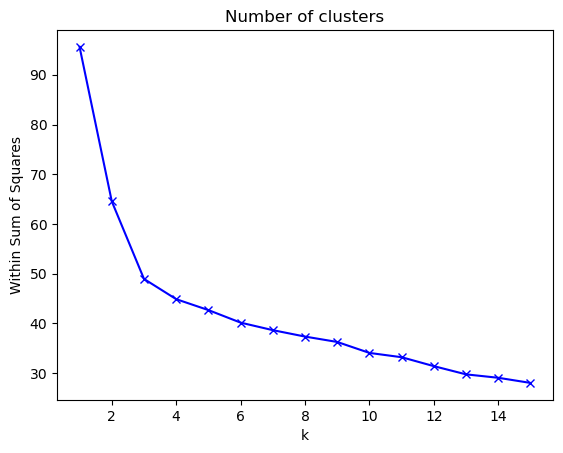

In [51]:
## We use a for loop to try different numbers of clusters
## For each k, we calculate the 'inertia' and record these values
WCSS = {}
K = range(1,16)
for k in K:
    km = KMeans(n_clusters=k, random_state=42).fit(wine_std)
    WCSS[f'{k}'] = km.inertia_

## Now we can plot to help us identify the 'optimal' value for k
plt.plot(K, WCSS.values(), 'bx-')
plt.xlabel('k')
plt.ylabel('Within Sum of Squares')
plt.title('Number of clusters')
plt.show()

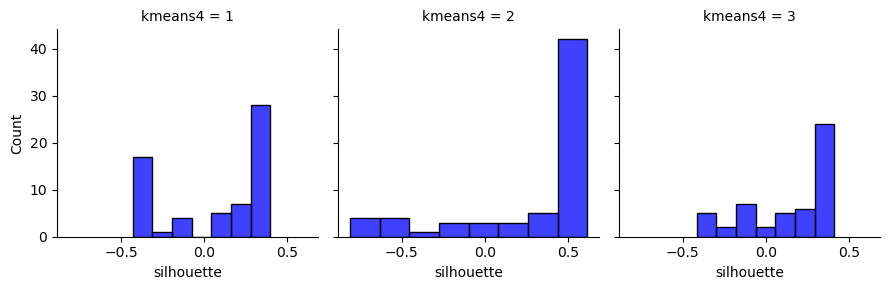

In [56]:
from sklearn.metrics import silhouette_score, silhouette_samples
silhouettes = silhouette_samples(X=wine[col_names],
labels=wine['kmeans4'])
wine["silhouette"] = silhouettes
g = sns.FacetGrid(wine, col="kmeans4")
g.map(sns.histplot, "silhouette")



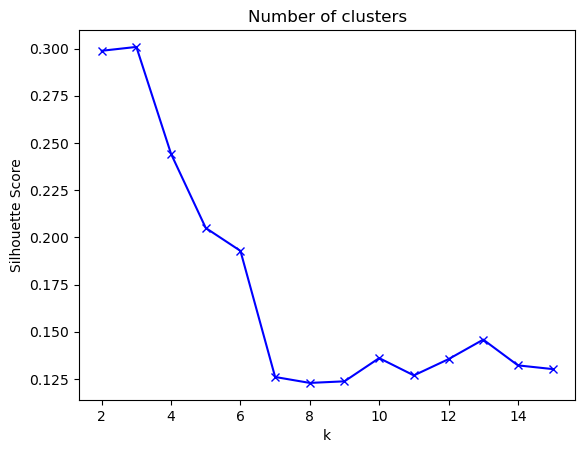

In [57]:
## We use a for loop to try different numbers of clusters
silhouettes = {}
K = range(2,16)
for k in K:
    km = KMeans(n_clusters=k, random_state=42).fit(wine_std)
    silhouettes[f'{k}'] = silhouette_score(X=wine_std,labels=km.labels_)

## Now we can plot to help us identify the 'optimal' value for k
plt.plot(K, silhouettes.values(), 'bx-')
plt.xlabel('k')
plt.ylabel('Silhouette Score')
plt.title('Number of clusters')
plt.show()